# MSCS 634 — Project Deliverable 1
## Data Collection, Cleaning, and Exploration

**Student:** Shawn  
**Course:** MSCS 634 — Data Mining  
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

### Introduction
For this project, I chose an online retail dataset from the UCI Machine Learning Repository. It has information about customer orders, products, prices, dates, and countries. I picked it because I can use it to look at buying habits and sales patterns, and I can keep using it for the next parts of this project.

Right now, my goal is to understand the data, clean up problems, and make graphs that show what's going on. I'm **not building a prediction model yet**. That comes in the later deliverables.

**Original dataset:** 541,909 rows and 8 columns, covering December 2010 through December 2011.  
**Source:** [UCI Machine Learning Repository — Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) · [DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33)  
**Note:** UCI lists the dataset under a CC BY 4.0 license. I kept the original Excel file unchanged.

## 1. Dataset details and why I chose it

The original file has **8 columns**, which meets the project's requirement for at least 8–10 attributes and 500 records. A row is a product entry on an invoice, **not necessarily one full order**.

| Column | What it means |
|---|---|
| `InvoiceNo` | Invoice number (invoices beginning with C are cancellations) |
| `StockCode` | Product code |
| `Description` | Product name or description |
| `Quantity` | Number of units on the line |
| `InvoiceDate` | Date and time of the transaction |
| `UnitPrice` | Price for one item, in British pounds (£) |
| `CustomerID` | Customer number, when available |
| `Country` | Country associated with the transaction |

The combination of product information, order dates, customer IDs, and amounts makes this a useful choice for **regression, classification, customer grouping, and shopping-basket patterns** later. A few rows are missing customer IDs, though, so I will need to be careful when I look at individual customers.

In [2]:
# Import the libraries used throughout the project.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

## 2. Load and inspect the original data

I load the **original Excel file** with Pandas. I check the first five rows, the number of records, column types, and summary statistics before making any changes.

In [6]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
# Keep Online Retail.xlsx in the same folder as this notebook.
raw_df = pd.read_excel("Online Retail.xlsx")
print(f"Original dataset: {raw_df.shape[0]:,} rows and {raw_df.shape[1]} columns")
print("Date range:", raw_df["InvoiceDate"].min(), "to", raw_df["InvoiceDate"].max())
print("\nFirst five rows:")
display(raw_df.head())
print("\nColumn information:")
raw_df.info()
print("\nSummary of numeric columns:")
display(raw_df[["Quantity", "UnitPrice"]].describe().round(2))

Original dataset: 541,909 rows and 8 columns
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Summary of numeric columns:


,Quantity,UnitPrice
count,"541,909.00","541,909.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


### What I noticed

The file has a lot of rows, but the structure is pretty easy to follow. I can see the price and quantity for each product entry, and the invoice number lets me group products that were bought together. I'll check for missing information and strange values before using the numbers to make any conclusions.

## 3. Check data quality

First, I count missing values and exact duplicate rows. I also check for **negative quantities**, prices of zero or less, and cancellation invoices. Those records need special attention because they don't represent a normal paid sale.

In [10]:
# Report missing values with both a count and a percentage.
missing_summary = pd.DataFrame({
    "Missing rows": raw_df.isna().sum(),
    "Percent missing": (raw_df.isna().mean() * 100).round(2)
})
print("Missing values:")
display(missing_summary)

# Count common issues. An invoice starting with C indicates a cancellation.
quality_checks = pd.DataFrame({
    "Check": ["Exact duplicate rows", "Cancellation invoice rows",
              "Quantity less than or equal to zero", "Unit price less than or equal to zero",
              "Blank or missing description"],
    "Rows": [raw_df.duplicated().sum(),
             raw_df["InvoiceNo"].astype(str).str.upper().str.startswith("C").sum(),
             (raw_df["Quantity"] <= 0).sum(),
             (raw_df["UnitPrice"] <= 0).sum(),
             raw_df["Description"].fillna("").astype(str).str.strip().eq("").sum()]
})
print("\nData quality checks (issues can overlap):")
display(quality_checks)

Missing values:


,Missing rows,Percent missing
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00



Data quality checks (issues can overlap):


,Check,Rows
0,Exact duplicate rows,5268
1,Cancellation invoice rows,9288
2,Quantity less than or equal to zero,10624
3,Unit price less than or equal to zero,2517
4,Blank or missing description,1454


### Why these issues matter

A missing product description makes it hard to tell what was sold. A missing customer ID is different: I can still use that row to study total sales, but I can't assign it to a specific customer. I also don't want to mix refunds with normal purchases when making sales charts. Finally, a very large order might be real, so I won't automatically delete it just because it's unusual.

## 4. Clean the data and explain the decisions

I keep `raw_df` unchanged and work on a copy. Here are my cleaning decisions:

1. Fix extra spaces in text and make product descriptions consistent.
2. Convert dates and numbers to the proper types.
3. Remove exact duplicate rows. These are identical entries, although a real purchase could sometimes look identical, so that's a limitation.
4. Remove records missing basic information needed for product sales analysis (such as the description or date).
5. Leave missing `CustomerID` values blank. Guessing customer IDs would make the customer analysis unreliable.
6. Set cancellation invoices aside and exclude zero/negative quantity or price lines from the **paid-sales dataset**. This is for exploring purchases, not calculating net revenue after returns.
7. Keep unusual **positive** sales amounts. I will show outliers in the analysis, but I won't assume that every big purchase is a mistake.

The original Excel file stays available so I can revisit returns and other excluded records in later deliverables.

In [11]:
# Make a separate working copy so the original data remains unchanged.
working_df = raw_df.copy()
audit = [("Original file", len(working_df))]

# Clean up inconsistent spacing and text formats.
for col in ["InvoiceNo", "StockCode", "Description", "Country"]:
    working_df[col] = working_df[col].astype("string").str.strip()
working_df["InvoiceNo"] = working_df["InvoiceNo"].str.upper()
working_df["StockCode"] = working_df["StockCode"].str.upper()
working_df["Description"] = (working_df["Description"]
    .str.replace(r"\s+", " ", regex=True).str.upper().replace("", pd.NA))
working_df["Country"] = (working_df["Country"]
    .str.replace(r"\s+", " ", regex=True).replace("", pd.NA))
working_df["InvoiceDate"] = pd.to_datetime(working_df["InvoiceDate"], errors="coerce")
working_df["Quantity"] = pd.to_numeric(working_df["Quantity"], errors="coerce")
working_df["UnitPrice"] = pd.to_numeric(working_df["UnitPrice"], errors="coerce")
# Use Pandas' nullable integer type so unknown customer IDs stay blank.
working_df["CustomerID"] = pd.to_numeric(
    working_df["CustomerID"], errors="coerce").astype("Int64")

# Remove rows that are exactly the same after normalizing text.
working_df = working_df.drop_duplicates().copy()
audit.append(("After removing exact duplicates", len(working_df)))

# These fields are needed for the sales analysis. CustomerID is intentionally NOT here.
required = ["InvoiceNo", "StockCode", "Description", "InvoiceDate",
            "Country", "Quantity", "UnitPrice"]
working_df = working_df.dropna(subset=required).copy()
audit.append(("After removing missing essential fields", len(working_df)))

# Treat cancellations/returns separately from completed paid sales.
cancellation_mask = working_df["InvoiceNo"].str.startswith("C", na=False)
returns_df = working_df.loc[cancellation_mask].copy()
working_df = working_df.loc[~cancellation_mask].copy()
audit.append(("After excluding cancellations", len(working_df)))

# Only keep entries with a positive quantity and unit price for paid-sales analysis.
valid_sales_mask = (working_df["Quantity"] > 0) & (working_df["UnitPrice"] > 0)
sales_df = working_df.loc[valid_sales_mask].copy()
audit.append(("Final paid-sales rows", len(sales_df)))

# Add useful columns without removing the original eight.
sales_df["LineTotal"] = sales_df["Quantity"] * sales_df["UnitPrice"]
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.day_name()
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

# Show exactly how many rows remained after each step.
audit_df = pd.DataFrame(audit, columns=["Cleaning step", "Rows remaining"])
audit_df["Rows removed in this step"] = -audit_df["Rows remaining"].diff().fillna(0).astype(int)
print("Cleaning summary:")
display(audit_df)
print("\nFinal paid-sales preview:")
display(sales_df.head())
print("\nRows with unknown CustomerID (kept):", f"{sales_df['CustomerID'].isna().sum():,}")
print("Cancellation rows kept separately in memory:", f"{len(returns_df):,}")

Cleaning summary:


,Cleaning step,Rows remaining,Rows removed in this step
0,Original file,541909,0
1,After removing exact duplicates,536641,5268
2,After removing missing essential fields,535187,1454
3,After excluding cancellations,525936,9251
4,Final paid-sales rows,524878,1058



Final paid-sales preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Month,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8



Rows with unknown CustomerID (kept): 132,186
Cancellation rows kept separately in memory: 9,251


### After cleaning

The table above shows how many rows I removed at each step. The goal wasn't to make the dataset as small as possible. I wanted a set of records that makes sense for looking at paid sales while still keeping the original data in case I need it later.

In [12]:
# Double-check the cleaned dataset before making charts.
print("Rows / columns:", sales_df.shape)
print("Missing values in essential fields:")
display(sales_df[required].isna().sum().to_frame("Missing"))
print("Exact duplicates left:", sales_df.duplicated().sum())
print("Cancelled invoices left:", sales_df["InvoiceNo"].str.startswith("C").sum())
print("Nonpositive sales lines left:", ((sales_df["Quantity"] <= 0) | (sales_df["UnitPrice"] <= 0)).sum())

assert sales_df[required].notna().all().all()
assert (sales_df["Quantity"] > 0).all() and (sales_df["UnitPrice"] > 0).all()
assert (sales_df["LineTotal"] > 0).all()
assert not sales_df["InvoiceNo"].str.startswith("C").any()

Rows / columns: (524878, 12)
Missing values in essential fields:


,Missing
InvoiceNo,0
StockCode,0
Description,0
InvoiceDate,0
Country,0
Quantity,0
UnitPrice,0


Exact duplicates left: 0
Cancelled invoices left: 0
Nonpositive sales lines left: 0


## 5. Exploratory data analysis (EDA)

Now I can look for patterns with graphs. I'll compare sales over time, countries, and order values. I'll also check how quantities and prices are related and look at unusually large sales. These plots are based on **positive sales lines only**, not a full accounting of refunds.

### Chart 1 — Sales by month

I add up `LineTotal` for each month to see how the paid-sales amounts changed over time. The first and last months don't cover equal lengths of time, so this is an overview rather than a fair month-to-month sales forecast.

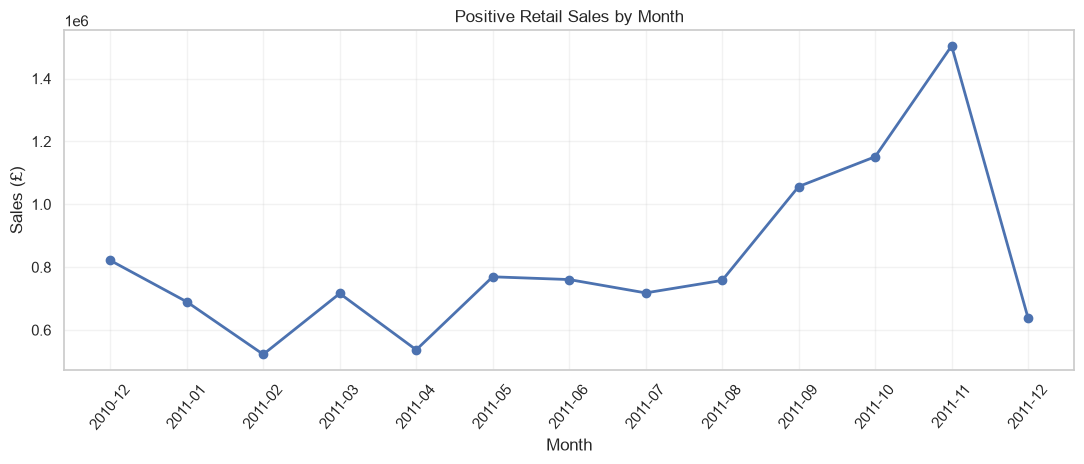

Highest month in these records: 2011-11 (£1,503,867)
Dates available: 2010-12-01 through 2011-12-09


In [13]:
monthly_sales = sales_df.groupby("Month", sort=True)["LineTotal"].sum()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(monthly_sales.index, monthly_sales.values, marker="o", linewidth=2)
ax.set_title("Positive Retail Sales by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (£)")
ax.tick_params(axis="x", rotation=50)
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURES / "01_monthly_sales.png", dpi=160, bbox_inches="tight")
plt.show()
print("Highest month in these records:", monthly_sales.idxmax(),
      f"(£{monthly_sales.max():,.0f})")
print("Dates available:", sales_df["InvoiceDate"].min().date(), "through",
      sales_df["InvoiceDate"].max().date())

**What I noticed:** Monthly sales aren't the same throughout the year. Some months have much larger totals than others. Since December 2011 only contains the first part of the month, I shouldn't compare it with complete months and assume business suddenly dropped. For future modeling, I could use the month and day of the week as helpful pieces of information, while making sure dates are handled in order.

### Chart 2 — Largest non-UK markets

The United Kingdom accounts for a big part of this dataset, so I leave it out **of this one chart** to make the smaller markets easier to compare. I don't remove UK orders from the cleaned file.

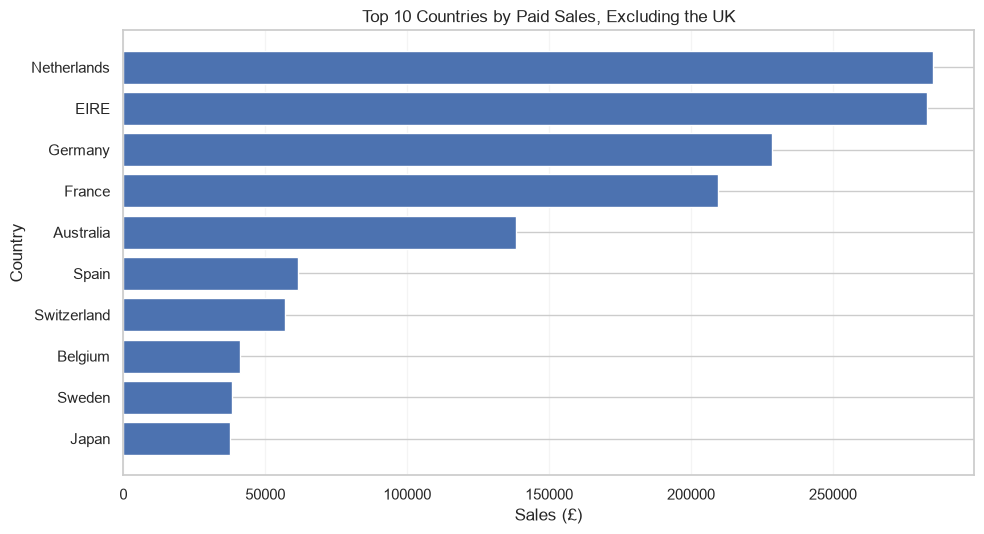

UK share of positive-sales total: 84.6%
Countries represented: 38


In [14]:
country_sales = sales_df.groupby("Country")["LineTotal"].sum().sort_values(ascending=False)
uk_share = country_sales.get("United Kingdom", 0) / country_sales.sum() * 100
outside_uk = country_sales.drop("United Kingdom", errors="ignore").head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(outside_uk.index, outside_uk.values)
ax.set_title("Top 10 Countries by Paid Sales, Excluding the UK")
ax.set_xlabel("Sales (£)")
ax.set_ylabel("Country")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURES / "02_non_uk_sales.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"UK share of positive-sales total: {uk_share:.1f}%")
print("Countries represented:", sales_df["Country"].nunique())

**What I noticed:** The store's sales are not spread evenly across countries. The UK makes up most of the sales, and some of the other countries make much smaller contributions. If I use country information in a model later, I'll need to remember that the largest market could have a much stronger influence than the smaller ones.

### Chart 3 — Distribution of transaction-line amounts

A single invoice can contain several products. `LineTotal` is the amount for **one product line**, calculated as quantity multiplied by unit price. I use a logarithmic x-axis to show small and large purchases on the same chart.

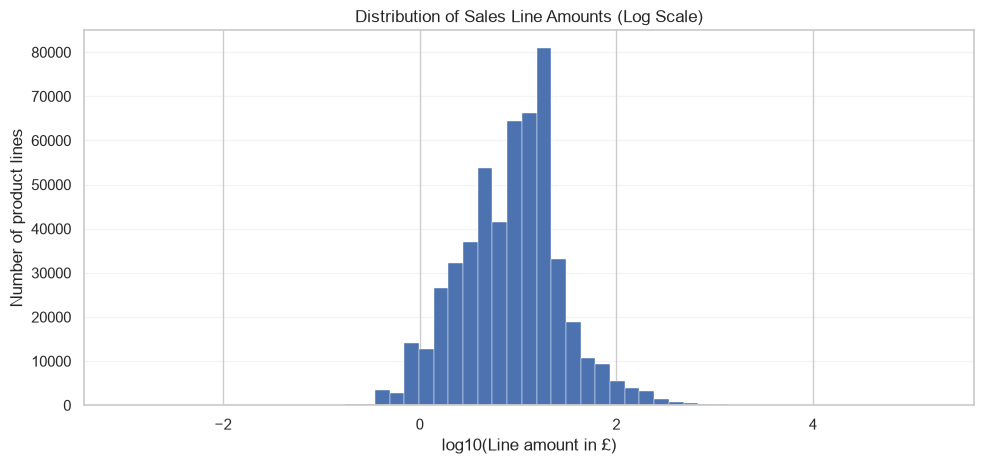

Median line amount: £9.92
Mean line amount: £20.28
99th percentile: £183.60


In [15]:
positive_line_values = sales_df["LineTotal"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.hist(np.log10(positive_line_values), bins=55, edgecolor="white", linewidth=0.3)
ax.set_title("Distribution of Sales Line Amounts (Log Scale)")
ax.set_xlabel("log10(Line amount in £)")
ax.set_ylabel("Number of product lines")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURES / "03_line_amount_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Median line amount: £{positive_line_values.median():,.2f}")
print(f"Mean line amount: £{positive_line_values.mean():,.2f}")
print(f"99th percentile: £{positive_line_values.quantile(.99):,.2f}")

**What I noticed:** Most product lines are fairly small, but some are much more expensive. That makes the average line amount larger than the median. For later machine learning work, I may need to use a log transformation or a method that isn't thrown off as much by a few very large values.

### Chart 4 — Invoice totals and unusually large orders

I add all product lines with the same invoice number to get the **invoice total**. A box plot can show how far the larger invoices are from the rest. To make the middle of the chart readable, I cap **only the displayed values** at the 99th percentile; the full invoice amounts stay in the data.

C:\Users\chazz\AppData\Local\Temp\ipykernel_5040\3881018483.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(invoice_totals.clip(upper=limit99), vert=False)


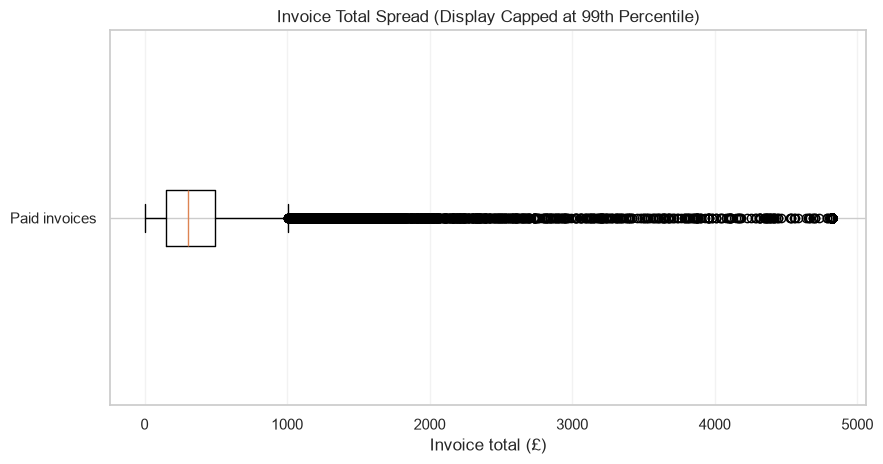

Number of paid invoices: 19,960
Median invoice amount: £303.30
99th percentile invoice amount: £4,821.17
Largest invoice amount (kept): £168,469.60
Top 5 highest invoice totals:


,Total (£)
InvoiceNo,
581483,"168,469.60"
541431,"77,183.60"
574941,"52,940.94"
576365,"50,653.91"
556444,"38,970.00"


In [16]:
invoice_totals = sales_df.groupby("InvoiceNo")["LineTotal"].sum()
limit99 = invoice_totals.quantile(.99)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.boxplot(invoice_totals.clip(upper=limit99), vert=False)
ax.set_title("Invoice Total Spread (Display Capped at 99th Percentile)")
ax.set_xlabel("Invoice total (£)")
ax.set_yticklabels(["Paid invoices"])
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURES / "04_invoice_total_boxplot.png", dpi=160, bbox_inches="tight")
plt.show()
print("Number of paid invoices:", f"{len(invoice_totals):,}")
print(f"Median invoice amount: £{invoice_totals.median():,.2f}")
print(f"99th percentile invoice amount: £{limit99:,.2f}")
print(f"Largest invoice amount (kept): £{invoice_totals.max():,.2f}")
print("Top 5 highest invoice totals:")
display(invoice_totals.nlargest(5).rename("Total (£)").to_frame())

**What I noticed:** A few invoices are much bigger than the usual order. I kept those orders because they might be real bulk purchases. The box plot is capped only so the more typical orders are easier to see. If I predict order values in the next deliverable, I'll need to check whether these large orders make model errors bigger.

### Chart 5 — Quantity compared with unit price

This scatter plot looks at whether product lines with bigger quantities usually have lower or higher prices per item. I use a repeatable random sample and hide the highest 1% **from the display only**, so the main pattern is easier to see.

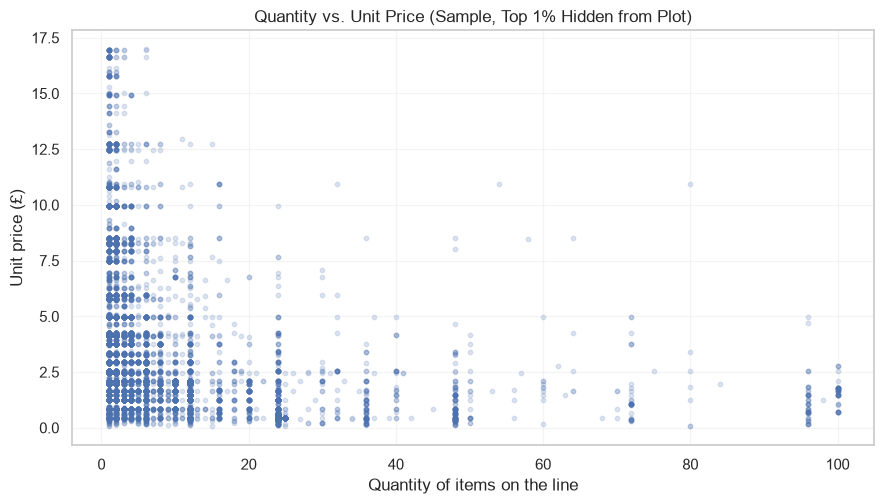

Correlation (all cleaned lines):


,Quantity,UnitPrice,LineTotal
Quantity,1.00,-0.00,0.91
UnitPrice,-0.00,1.00,0.14
LineTotal,0.91,0.14,1.00


In [17]:
# Sample for readability; the saved cleaned dataset is NOT sampled or trimmed.
plot_sample = sales_df[["Quantity", "UnitPrice"]].sample(
    n=min(12000, len(sales_df)), random_state=42)
qty_cap = sales_df["Quantity"].quantile(.99)
price_cap = sales_df["UnitPrice"].quantile(.99)
plot_sample = plot_sample.loc[(plot_sample["Quantity"] <= qty_cap) &
                              (plot_sample["UnitPrice"] <= price_cap)]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(plot_sample["Quantity"], plot_sample["UnitPrice"], alpha=.18, s=10)
ax.set_title("Quantity vs. Unit Price (Sample, Top 1% Hidden from Plot)")
ax.set_xlabel("Quantity of items on the line")
ax.set_ylabel("Unit price (£)")
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURES / "05_quantity_vs_price.png", dpi=160, bbox_inches="tight")
plt.show()

print("Correlation (all cleaned lines):")
display(sales_df[["Quantity", "UnitPrice", "LineTotal"]].corr().round(3))

**What I noticed:** The amounts and prices don't follow one simple pattern. Some lines have a lot of low-price items, while others have only a few higher-price items. Also, `LineTotal` is calculated directly from quantity and price, so I should **not** use both of those numbers as inputs to predict `LineTotal` and pretend that is a meaningful discovery. That would give the model an unfair shortcut.

## 6. What I learned and how it helps the next deliverables

The biggest thing I learned is that the original file has different kinds of records mixed together. Some are normal purchases, some are cancellations, and some are missing information. Cleaning those up changed what the dataset represents, so I need to explain that difference.

For the next deliverables, I plan to use this dataset in a few ways:

- **Regression (Deliverable 2):** Predict the total for an invoice using information available before the final invoice total is known, such as the order size and timing. I'll compare two models and avoid giving them the exact answer as an input. I'll split data by time where practical.
- **Classification (Deliverable 3):** Sort invoices into lower- and higher-value groups using a clear threshold. I'll avoid including the final invoice total among the predictors.
- **Clustering (Deliverable 3):** Group customers using how recently they bought something, how often they ordered, and how much they spent. I'll only use transactions that have a real `CustomerID` for that task.
- **Association rules (Deliverable 3):** Look for products that tend to appear on the same invoice by using `InvoiceNo` and `StockCode`.

The main limitations are the missing customer IDs, very large orders, and the fact that we're looking at one retailer for a limited period. These findings are useful for this dataset, but they don't automatically describe every online store.

## 7. Save the cleaned data for the next deliverable

I save the paid-sales records as a compressed CSV because this is a large dataset. Pandas can read it directly later. The original Excel file is also included, so I can go back and review cancellations and other excluded records if I need to.

In [18]:
# Compressed CSV keeps the original row details without creating an oversized GitHub file.
sales_df.to_csv("Online_Retail_Cleaned.csv.gz", index=False, compression={"method": "gzip", "compresslevel": 1})

# A small audit CSV shows each cleaning step and its row count.
audit_df.to_csv("cleaning_audit.csv", index=False)

print("Saved: Online_Retail_Cleaned.csv.gz")
print("Saved: cleaning_audit.csv")
print(f"Cleaned lines: {len(sales_df):,}; original: {len(raw_df):,}")
print("Cleaned data preview:")
display(pd.read_csv("Online_Retail_Cleaned.csv.gz", nrows=5).head())

Saved: Online_Retail_Cleaned.csv.gz
Saved: cleaning_audit.csv
Cleaned lines: 524,878; original: 541,909
Cleaned data preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Month,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## Conclusion

In this first deliverable, I learned how to load real sales data, check it for problems, clean it, and make graphs to understand it better. The graphs showed me that sales change across months and countries, and that a small number of orders are much larger than most others. The cleaning decisions also mattered because refunds and missing IDs can change the meaning of the results. I kept the original data and saved a cleaned version so I can use both as I move into modeling.

**Dataset credit:** Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33